# Iteration 2 Data and Simulation Check

We load MovieLens 100K, look at it piece by piece, and turn it into the rating matrix R. Then we build a small rating matrix ourselves where we know every value, hide most of it, and check that ALS can find the hidden values. Loading and simulation functions are in `src/` (the project rules ask for code there), everything else is in this notebook.

#### Setup

In [1]:
#import all necessary libraries
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#letting python find our files in the src folder
sys.path.append(str(Path.cwd().parent / "src"))
import load_data as ld
import simulate as sim

#folder where we save plots for the report
FIGURES = Path.cwd().parent / "figures"

### Real Data MovieLens 100K

#### Loading

In [2]:
#reading the ratings file
ratings = ld.load_ratings()

In [3]:
#looking at first five rows
ratings.head()

,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


Every row is one rating, which shows the user, the movie, how many stars (1 to 5) and when it was given (timestamp in seconds). So the data is a long list of ratings and not yet a table of users and movies.

In [4]:
#number of rows and columns
ratings.shape

(100000, 4)

In [5]:
#checking types of columns
ratings.dtypes

user_id      int64
movie_id     int64
rating       int64
timestamp    int64
dtype: object

We have 100,000 ratings and 4 columns, and all of them are whole numbers (int64), which is what we expect for ids, stars and seconds. So no type fixing is needed.

In [6]:
#how many missing values we have per column
ratings.isna().sum()

user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64

No missing values in the ratings, so we do not need to remove any rows.

In [7]:
#reading the movies file to see titles
movies = ld.load_movies()
movies.shape

(1682, 24)

In [8]:
#missing values in the movie columns we might use
movies[["movie_id", "title", "release_date"]].isna().sum()

movie_id        0
title           0
release_date    1
dtype: int64

One movie has no release date. We do not use release dates in the project, so we leave it as it is.

In [9]:
#how many different users and movies
print("users", ratings["user_id"].nunique())
print("movies", ratings["movie_id"].nunique())

users 943
movies 1682


943 users and 1,682 movies, same as the dataset description, so nothing is lost while loading.

#### Rating matrix R

Next we turn the long list into the matrix R, where one row is one user, one column is one movie and one cell is the stars that user gave to that movie.

In [10]:
#building R and the mask of known cells
R, mask = ld.build_rating_matrix(ratings)
R.shape

(943, 1682)

Together with R we build `mask`, a table of the same size with True where a rating exists and False where it does not. We need it because R has 0 in every empty cell, but 0 is not a rating (stars go from 1 to 5), it only means we do not know. So the mask tells the code which cells are real ratings, and later the error is counted only on those cells. In the math this set of known cells is called Ω.

In [11]:
#user 1 (row 0) on the first 3 movies and on movies 273 to 275
print("R on movies 1 to 3", R[0, :3], "mask", mask[0, :3])
print("R on movies 273 to 275", R[0, 272:275], "mask", mask[0, 272:275])

R on movies 1 to 3 [5. 3. 4.] mask [ True  True  True]
R on movies 273 to 275 [0. 0. 0.] mask [False False False]


User 1 gave 5, 3 and 4 stars to the first three movies, so the mask is True there. On movies 273 to 275 R shows 0 and the mask is False, so these zeros are empty cells and not ratings.

In [12]:
#how many cells have a rating and what share of all cells it is
known_cells = mask.sum()
all_cells = R.shape[0] * R.shape[1]
print("known cells", known_cells, "out of", all_cells)
print("filled percent", round(known_cells / all_cells * 100, 2))

known cells 100000 out of 1586126
filled percent 6.3


Only 6.3% of the matrix has a rating, so 93.7% of the cells are empty. Guessing these empty cells is the whole job of our method, so the data fits the problem well.

#### Ratings

In [13]:
#how many times each star value is given
star_counts = ratings["rating"].value_counts().sort_index()
star_counts

rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64

In [14]:
#average rating and how spread out ratings are
print("mean", round(ratings["rating"].mean(), 2))
print("variance", round(ratings["rating"].var(), 2))

mean 3.53
variance 1.27


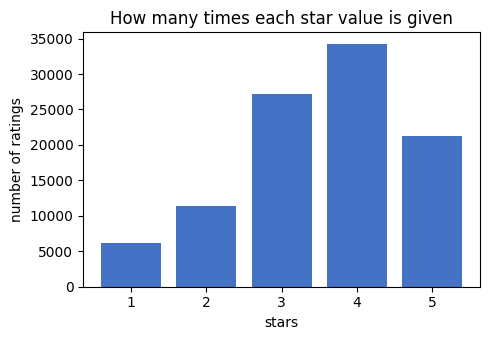

In [15]:
#bar chart of star values
plt.figure(figsize=(5, 3.5))
plt.bar(star_counts.index, star_counts.values, color="#4472C4")  #one bar per star value
plt.xlabel("stars")
plt.ylabel("number of ratings")
plt.title("How many times each star value is given")
plt.tight_layout()                                              #keep labels inside the picture
plt.savefig(FIGURES / "rating_counts.png", dpi=150)             #save for the report
plt.show()

People give 4 stars most often (34,174 times) and 1 star least often (6,110 times). The mean is 3.53 and the variance is 1.27. So a model that always guesses 3.53 is a simple baseline, and our method has to do better than it.

#### Ratings per user and per movie

In [16]:
#number of ratings for every user (sum along each row of the mask)
per_user = mask.sum(axis=1)
print("min", per_user.min(), "median", np.median(per_user), "max", per_user.max())

min 20 median 65.0 max 737


In [17]:
#number of ratings for every movie (sum along each column of the mask)
per_movie = mask.sum(axis=0)
print("min", per_movie.min(), "median", np.median(per_movie), "max", per_movie.max())

min 1 median 27.0 max 583


In [18]:
#movies that only one person rated
(per_movie == 1).sum()

np.int64(141)

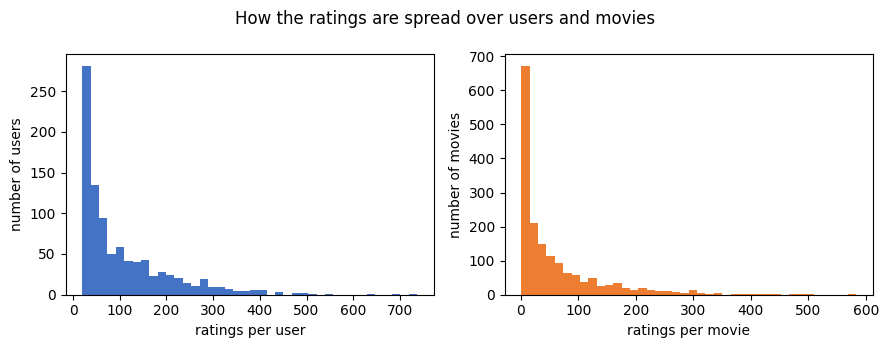

In [19]:
#two histograms side by side
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

axes[0].hist(per_user, bins=40, color="#4472C4")      #left picture is users
axes[0].set_xlabel("ratings per user")
axes[0].set_ylabel("number of users")

axes[1].hist(per_movie, bins=40, color="#ED7D31")     #right picture is movies
axes[1].set_xlabel("ratings per movie")
axes[1].set_ylabel("number of movies")

fig.suptitle("How the ratings are spread over users and movies")
plt.tight_layout()
plt.savefig(FIGURES / "ratings_per_user_and_movie.png", dpi=150)
plt.show()

Every user rated at least 20 movies, a typical (median) user rated 65 and the most active one rated 737. Movies are more uneven, a typical movie has 27 ratings, but 141 movies have only one. So for rare movies we have very little information and their guesses will be less reliable than for popular ones.

#### Train and test split

In [20]:
#official split given by MovieLens
train = ld.load_ratings("u1.base")
test = ld.load_ratings("u1.test")
print("train rows", len(train), "test rows", len(test))

train rows 80000 test rows 20000


MovieLens gives a ready split with 80,000 ratings for training and 20,000 for testing. We will use it in Iteration 3 because the instructions ask every team to use it, so our test error can be compared with other teams.

### How ALS Works

**What it does.** ALS (alternating least squares) fills the empty cells of R. It looks for two thin matrices, U with one row per user and V with one row per movie, each row only k numbers long. The guess for user u and movie i is the dot product of row u of U and row i of V, so the whole table of guesses is U times V transposed. The goal is to make the guesses close to the known ratings, which is the objective J from question 1.

**How it works.** Finding U and V together is hard, because the guess is U times V and both are unknown. But if we fix V, then for every user the problem becomes ordinary least squares (the same kind of problem as fitting a line), which has an exact answer from the normal equations in question 2. So ALS goes in turns.
1. Start with random U and V.
2. Fix V. For every user take only the movies this user rated and solve a small k by k system to get the best row of U.
3. Fix U. For every movie take only the users who rated it and solve a small k by k system to get the best row of V.
4. Repeat steps 2 and 3 until J stops going down.

**Why it works.** Every half step picks the best possible U (or V) for the current V (or U). The old U was one of the options, so the new J can only be smaller or the same, which is question 4. And the system always has an answer because of λ, which is question 3.

**Why it fits our dataset.** Our R is 93.7% empty, and ALS only ever uses the known cells, so we never have to invent values for the empty ones. Each user rated at least 20 movies, which is plenty to solve a system with only k unknowns. And with 943 users and 1,682 movies every system is tiny (k by k), so a full step is fast. The main assumption is that ratings follow a few patterns (low rank), so people who liked the same movies before will like the same movies again. So ALS is a good fit if that assumption holds, and the simulation below checks the method on data where it holds for sure.

### Simulation with a Known Answer

On real data we never know what is behind an empty cell, so we cannot check if a guess is right. So here we make our own small rating matrix where we know every value, hide most of it from ALS, let ALS guess the hidden part, and then compare the guesses with the values we hid.

The size is 100 users by 80 movies because the Iteration 2 handout gives these numbers. A small matrix runs in a second and every team member gets the same result with seed 0, and it is still big enough to have thousands of hidden cells to check. The values are not stars from 1 to 5, they are just numbers around 0, because here we only test if the method finds the structure, not the star scale.

#### Building the matrix

In [21]:
#settings from the handout
nu = 100      #number of users
ni = 80       #number of movies
k = 3         #true rank
frac = 0.3    #share of cells we keep
lam = 1.0     #lambda the penalty weight
seed = 0

R_sim, R_true, mask_sim = sim.simulate_ratings(nu, ni, k, frac, seed)
R_sim.shape

(100, 80)

The rank of a matrix is how many rows we need so that every other row is a mix of them. We build R_true as (100 by 3) times (3 by 80), so every user's row is a mix of the same 3 basic rows, and the rank is 3. In movie terms it means all 100 users' tastes come from only 3 patterns. ALS with k = 3 looks for exactly these 3 patterns, so if it works it should find the hidden values.

In [22]:
#rank of the true matrix (must be 3)
np.linalg.matrix_rank(R_true)

np.int64(3)

In [23]:
#singular values of the true matrix, only the first 3 are not zero
s_true = np.linalg.svd(R_true, compute_uv=False)
s_true[:6].round(4)

array([100.1131,  87.2692,  85.2752,   0.    ,   0.    ,   0.    ])

Only the first 3 singular values are bigger than zero and the rest are 0, which is another way to see rank 3. So R_true really has 3 patterns and nothing more.

Next we hide cells. Each cell is kept with chance 0.3 and hidden otherwise, so ALS sees only about 30% of the matrix, like real ratings where most cells are empty (93.7% in MovieLens). We keep the hidden values aside, because those are the answers we check against.

In [24]:
#how many cells we kept and how many are hidden
print("kept", mask_sim.sum(), "share", round(mask_sim.mean(), 3))
print("hidden", (~mask_sim).sum())

kept 2281 share 0.285
hidden 5719


In [25]:
#fewest and most kept cells for one user
kept_per_user = mask_sim.sum(axis=1)
print("min", kept_per_user.min(), "max", kept_per_user.max())

min 10 max 32


We kept 2,281 cells (28.5%), not exactly 30%, because each cell is kept at random with chance 0.3. Every user still has between 10 and 32 known cells, which is more than the 3 unknowns of their row in U. So ALS has enough information for every user and has to guess 5,719 hidden values.

#### Running ALS

In [26]:
#50 steps of alternating least squares
U, V, J_hist = sim.als(R_sim, mask_sim, k=k, lam=lam, iters=50, seed=seed)
print("U", U.shape, "V", V.shape)

U (100, 3) V (80, 3)


To see what one step of ALS does, we redo the update of user 1 (row 0) by hand with the final V and check that we get the same row of U.

In [27]:
#movies that user 1 can see
seen = mask_sim[0]
print("movies user 1 can see", seen.sum())

#rows of V for those movies and the ratings user 1 gave them
V_u = V[seen]
r_u = R_sim[0, seen]
print("V_u", V_u.shape, "r_u", r_u.shape)

movies user 1 can see 30
V_u (30, 3) r_u (30,)


In [28]:
#the two sides of the system from question 2
left = V_u.T @ V_u + lam * np.eye(k)
right = V_u.T @ r_u
print(left.round(2))
print(right.round(2))

[[45.06  0.51 -0.18]
 [ 0.51 29.82 -0.64]
 [-0.18 -0.64 30.86]]
[-25.46   1.22 -10.09]


In [29]:
#solving the 3 by 3 system and comparing with the row ALS found
u_by_hand = np.linalg.solve(left, right)
print("by hand", u_by_hand.round(4))
print("from ALS", U[0].round(4))

by hand [-0.5668  0.0436 -0.3294]
from ALS [-0.5668  0.0436 -0.3294]


User 1 can see 30 movies, so V_u has 30 rows, but the system to solve is only 3 by 3 because k = 3. The row we get by hand is the same as the one ALS found. So one ALS update is exactly the small system from question 2.

In [30]:
#objective J before the first step and after the last one
print("J at start", round(J_hist[0], 2))
print("J at end", round(J_hist[-1], 2))

J at start 15227.41
J at end 546.68


In [31]:
#change of J between two steps in a row (must never be positive)
changes = np.diff(J_hist)
print("largest change", changes.max())
print("never increases", np.all(changes <= 1e-9))

largest change -2.356241361667344e-05
never increases True


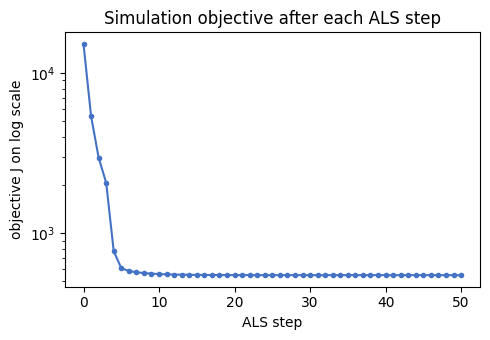

In [32]:
#J after every step on a log scale
plt.figure(figsize=(5, 3.5))
plt.semilogy(J_hist, marker=".", color="#4472C4")   #log scale so small changes at the end are visible
plt.xlabel("ALS step")
plt.ylabel("objective J on log scale")
plt.title("Simulation objective after each ALS step")
plt.tight_layout()
plt.savefig(FIGURES / "simulation_objective.png", dpi=150)
plt.show()

J drops from 15,227 to 547 and the largest change between two steps is negative, so J never went up in any of the 50 steps. Most of the drop happens in the first 5 steps and then it flattens. So ALS behaves the way question 4 says it must.

#### Comparing guesses with the hidden truth

Now we take the cells we hid from ALS and put next to each other the true value (from R_true, which ALS never saw) and the guess. The closer they are, the better the method. We do the same for the filled SVD, which is the comparison method.

In [33]:
#guesses of both methods for every cell
guess_als = U @ V.T
guess_svd = sim.svd_baseline(R_sim, mask_sim, k)

#first 5 hidden cells side by side
hidden = np.argwhere(~mask_sim)[:5]
rows = []
for user, movie in hidden:
    rows.append({"user": user + 1, "movie": movie + 1,
                 "true": R_true[user, movie],
                 "ALS guess": guess_als[user, movie],
                 "SVD guess": guess_svd[user, movie]})
pd.DataFrame(rows).round(2)

,user,movie,true,ALS guess,SVD guess
0,1,1,-0.54,-0.54,-0.19
1,1,2,-0.97,-0.94,-0.18
2,1,3,-0.49,-0.50,-0.22
3,1,4,0.24,0.30,-0.12
4,1,7,-0.40,-0.40,-0.24


On these cells the ALS guess is almost the same as the true value, while the SVD guess is far off and close to 0. To say it with one number for all 5,719 hidden cells we use RMSE (root mean squared error), which is the typical size of one wrong guess.

In [34]:
#ALS error on hidden cells
sim.rmse(guess_als, R_true, ~mask_sim)

np.float64(0.14661396149625158)

In [35]:
#filled SVD error on hidden cells
sim.rmse(guess_svd, R_true, ~mask_sim)

np.float64(1.39388333485469)

In [36]:
#guessing zero everywhere, just for scale
guess_zero = np.zeros_like(R_true)
sim.rmse(guess_zero, R_true, ~mask_sim)

np.float64(1.7642483098404131)

ALS is off by about 0.15 per hidden cell, close to the noise of 0.1 we added, and nothing can guess random noise. Filled SVD is off by about 1.39, which is almost as bad as guessing zero everywhere (1.76). SVD does badly because it needs a full matrix, so we fill 70% of it with the mean, and then SVD learns those made up values. So ALS finds the hidden structure and SVD does not when most of the matrix is missing, which is what question 5 says.

In [37]:
#three users and three movies
  #user 2 gave half the stars of user 1 on every movie
  #user 3 rated exactly like user 1
tiny = np.array([[4, 2, 4],
                   [2, 1, 2],
                   [4, 2, 4]])
print(np.linalg.matrix_rank(tiny))

  #now user 3 has a different taste
tiny2 = np.array([[4, 2, 4],
                    [2, 1, 2],
                    [1, 5, 2]])
print(np.linalg.matrix_rank(tiny2))

1
2
